# Assignment 2

In this assignment, you will be working on an image classification task (codename `pnp`) using the transfer learning technique.
The task objective is to determine whether an image contains a person (`pnp` stands for person / non-person) -- a binary classification task.

This is the **PyTorch + PyTorch Lightning** variant of the assignment: the pre-trained model comes from
[torchvision](https://docs.pytorch.org/vision/stable/models.html), the model is written with plain PyTorch
modules (`torch.nn`), and trained with [PyTorch Lightning](https://lightning.ai/docs/pytorch/stable/).

The only difference in the submission is the model file: instead of `model.keras` and `model_architecture.json`,
this notebook saves `model.pt2` (the model exported with `torch.export`) and `model_summary.txt`.

## Dataset
* Dataset contains 80K images with known labels (for model development), and 20K images with unknown labels (for scoring).
* Dataset has been created from a subset of COCO Dataset, and so all copyrights belong to the original authors: https://cocodataset.org/#termsofuse
* Images have been rescaled and padded to be of shape (224, 224, 3).

While it's possible to create a new model architecture and train a model specifically for this task, that would be expensive in terms of time and cloud resources.
Instead, in this assignment, you will be re-using a pre-trained model's architecture and parameters to save time and cloud resources.

In [1]:
!ls pnp_dataset.zip || (aws s3 cp s3://danylo-ucla/pnp_dataset.zip ./)

pnp_dataset.zip


In [2]:
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

In [3]:
# Run this cell to check which PyTorch version and device (GPU or CPU) you are using.
import torch
print('PyTorch version:', torch.__version__)

# Models and tensors will be moved to this device.
# The notebook also runs without a GPU (e.g. on an ml.t3 instance), but much slower.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')

PyTorch version: 2.14.1+cu126
PyTorch device: NVIDIA A100-SXM4-40GB


In [4]:
from collegium.m02_cnn.utils.pnp_dataset_torch import PnpDataset

# PnpDataset is a PyTorch Dataset that reads the images directly from pnp_dataset.zip.
# Each image is a uint8 tensor of shape (3, 224, 224): PyTorch puts the color channels first,
# while Keras (and matplotlib) put them last, i.e. (224, 224, 3).
# See the torch.utils.data API for details:
# https://docs.pytorch.org/docs/stable/data.html
train_ds = PnpDataset('train', include_labels=True)
score_ds = PnpDataset('score', include_labels=False)
len(train_ds), len(score_ds)

(80000, 20000)

tensor(1.)

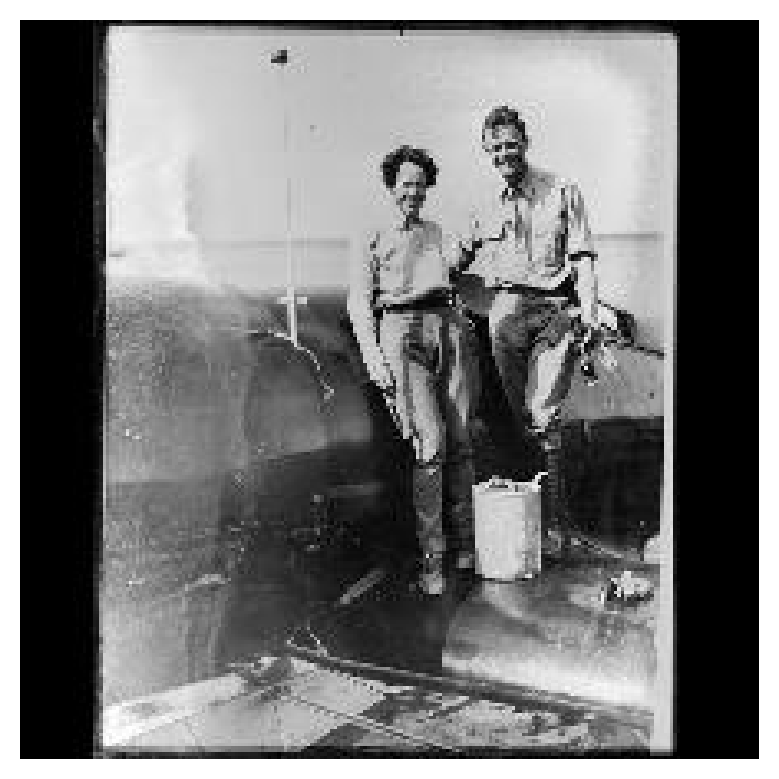

In [5]:
train_sample_x, train_sample_y = train_ds[0]
# permute moves the channels last for plotting: (3, 224, 224) -> (224, 224, 3)
plt.imshow(train_sample_x.permute(1, 2, 0))
plt.axis('off')
train_sample_y

tensor(0.)

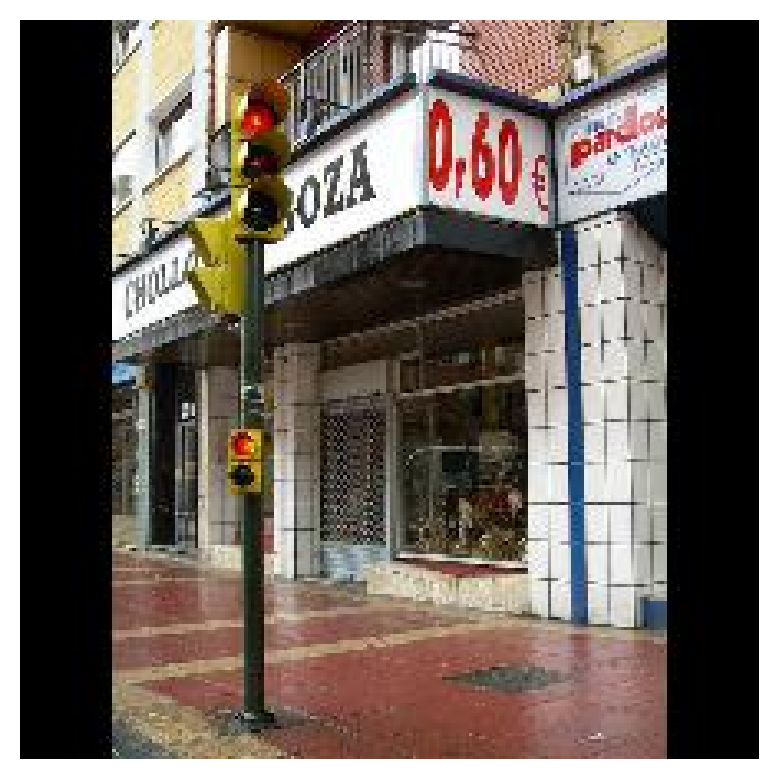

In [6]:
train_sample_x, train_sample_y = train_ds[1]
plt.imshow(train_sample_x.permute(1, 2, 0))
plt.axis('off')
train_sample_y

In [7]:
import torchvision
from torch import nn

# See https://docs.pytorch.org/vision/stable/models.html#classification for more options of pre-trained models.
# Note that the models with a .features attribute (MobileNet, EfficientNet, ConvNeXt) work with the code below.
backbone_name = 'mobilenet_v3_small'
# backbone_name = 'mobilenet_v3_large'
# backbone_name = 'efficientnet_b0'
# backbone_name = 'efficientnet_b1'
# backbone_name = 'efficientnet_b2'
# backbone_name = 'efficientnet_b3'
# backbone_name = 'efficientnet_b4'
# backbone_name = 'efficientnet_v2_s'
# backbone_name = 'convnext_tiny'

# Downloads the parameters pre-trained on the ImageNet dataset.
weights = torchvision.models.get_model_weights(backbone_name).DEFAULT
pretrained = torchvision.models.get_model(backbone_name, weights=weights)

# The pre-trained model is an ImageNet classifier: convolutional feature extractor + classification head.
# We only re-use the feature extractor (the "backbone"), and will train a new head for our task.
backbone = pretrained.features

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /home/sagemaker-user/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


  0%|          | 0.00/9.83M [00:00<?, ?B/s]

100%|██████████| 9.83M/9.83M [00:00<00:00, 290MB/s]

In [8]:
# The pre-trained model expects pixels scaled to [0, 1] and then normalized
# with the mean and standard deviation of each color channel in ImageNet.
# This module does that inside the model, so the model accepts raw pixel values (0..255),
# just like the images from PnpDataset (and like the Keras variant of this assignment).
class Normalize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer('mean', torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor(std).view(1, 3, 1, 1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return (x.float() / 255 - self.mean) / self.std

# ImageNet statistics of the pre-trained weights' preprocessing.
normalize = Normalize(mean=weights.transforms().mean, std=weights.transforms().std)
normalize.mean.flatten(), normalize.std.flatten()

(tensor([0.4850, 0.4560, 0.4060]), tensor([0.2290, 0.2240, 0.2250]))

In [9]:
# Freezes the parameters of the backbone, so they will not update during training.
# These parameters are initialized to a pre-trained snapshot using the ImagetNet dataset.
for parameter in backbone.parameters():
    parameter.requires_grad = False

In [10]:
from torchinfo import summary

# torchinfo shows the layers, their output shapes and number of parameters,
# like Keras' model.summary(). Frozen parameters are counted as non-trainable.
summary(backbone, input_size=(1, 3, 224, 224), depth=2, device='cpu')

Layer (type:depth-idx)                        Output Shape              Param #
Sequential                                    [1, 576, 7, 7]            --
├─Conv2dNormActivation: 1-1                   [1, 16, 112, 112]         --
│    └─Conv2d: 2-1                            [1, 16, 112, 112]         (432)
│    └─BatchNorm2d: 2-2                       [1, 16, 112, 112]         (32)
│    └─Hardswish: 2-3                         [1, 16, 112, 112]         --
├─InvertedResidual: 1-2                       [1, 16, 56, 56]           --
│    └─Sequential: 2-4                        [1, 16, 56, 56]           (744)
├─InvertedResidual: 1-3                       [1, 24, 28, 28]           --
│    └─Sequential: 2-5                        [1, 24, 28, 28]           (3,864)
├─InvertedResidual: 1-4                       [1, 24, 28, 28]           --
│    └─Sequential: 2-6                        [1, 24, 28, 28]           (5,416)
├─InvertedResidual: 1-5                       [1, 40, 14, 14]           --
│ 

In [11]:
# The number of channels in the backbone's output (e.g. 576 for mobilenet_v3_small).
with torch.no_grad():
    backbone_channels = backbone.eval()(torch.zeros(1, 3, 224, 224)).shape[1]

network = nn.Sequential(
    normalize,
    backbone,
    # Averages each channel over the 7x7 grid, then flattens to a vector of backbone_channels.
    nn.AdaptiveAvgPool2d(output_size=1),
    nn.Flatten(),
    # One output: the logit of the image containing a person.
    # The sigmoid is applied in the loss function (and in predict), not in the network.
    nn.Linear(in_features=backbone_channels, out_features=1),
    nn.Flatten(start_dim=0),
)

In [12]:
import lightning as L
import torch.nn.functional as F
import torchmetrics


# A LightningModule holds the network together with its training logic:
# the loss function, the logged metrics, and the optimizer.
# It plays the role of Keras' model.compile(...).
class PnpClassifier(L.LightningModule):
    def __init__(self, network: nn.Module, learning_rate: float):
        super().__init__()
        self.network = network
        self.learning_rate = learning_rate
        self.train_accuracy = torchmetrics.classification.BinaryAccuracy(threshold=0.5)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)

    def train(self, mode: bool = True):
        super().train(mode)
        # Lightning switches the whole model to training mode before training.
        # Keep the frozen layers in evaluation mode, so that BatchNorm uses (and does not update)
        # the pre-trained statistics, and Dropout is disabled -- like Keras does with trainable=False.
        for module in self.network.modules():
            parameters = list(module.parameters())
            if parameters and not any(p.requires_grad for p in parameters):
                module.eval()
        return self

    def training_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        # Binary cross-entropy, computed from the logits (more stable than sigmoid + log).
        loss = F.binary_cross_entropy_with_logits(logits, y)
        self.train_accuracy(torch.sigmoid(logits), y)
        # on_epoch=True averages the metrics over the epoch, like Keras' fit() output.
        self.log('loss', loss, on_step=False, on_epoch=True, prog_bar=True)
        self.log('binary_accuracy', self.train_accuracy, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def configure_optimizers(self):
        # SGD optimizer on the trainable parameters only. Other optimizers can also be used.
        trainable = [p for p in self.parameters() if p.requires_grad]
        return torch.optim.SGD(trainable, lr=self.learning_rate)


model = PnpClassifier(network, learning_rate=0.01)
batch_size = 128

In [13]:
summary(model, input_size=(1, 3, 224, 224), depth=1, device='cpu')

Layer (type:depth-idx)                                  Output Shape              Param #
PnpClassifier                                           [1]                       --
├─Sequential: 1-1                                       [1]                       927,585
Total params: 927,585
Trainable params: 577
Non-trainable params: 927,008
Total mult-adds (Units.MEGABYTES): 54.91
Input size (MB): 0.60
Forward/backward pass size (MB): 22.63
Params size (MB): 3.71
Estimated Total Size (MB): 26.94

In [14]:
from torch.utils.data import DataLoader
import logging
import os
import warnings

# Hide Lightning's informational messages printed at the start of each training
# (the device is already printed by the GPU cell above).
logging.getLogger('lightning.pytorch').setLevel(logging.WARNING)
# Lightning warns that the model is in evaluation mode (the frozen backbone, see PnpClassifier.train).
warnings.filterwarnings('ignore', '.*in eval mode.*')
# A deprecation warning inside Lightning itself, not caused by this notebook.
warnings.filterwarnings('ignore', '.*LeafSpec.*')

# Decoding the JPEG images is the bottleneck of the training,
# so the DataLoader decodes them in parallel worker processes.
# The workers send the batches through shared memory (/dev/shm), so more workers need more of it.
num_workers = min(os.cpu_count(), 8)


# Prints the metrics at the end of each epoch, like Keras' model.fit().
class PrintMetrics(L.Callback):
    def on_train_epoch_end(self, trainer, model):
        metrics = ' - '.join(f'{name}: {value.item():.4f}' for name, value in sorted(trainer.callback_metrics.items()))
        print(f'Epoch {trainer.current_epoch + 1}/{trainer.max_epochs} - {metrics}')


L.seed_everything(11)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers)

trainer = L.Trainer(
    # It's a good idea to have low number of epochs,
    # to test the learning process, but not for the final model training.
    max_epochs=1,
    accelerator=device.type,
    devices=1,
    # On a GPU, precision='16-mixed' makes larger backbones train faster.
    callbacks=[PrintMetrics()],
    # The model is saved below with save_model, so Lightning's logs and checkpoints are not needed.
    logger=False,
    enable_checkpointing=False,
    enable_model_summary=False,
)
trainer.fit(model, train_dataloaders=train_loader)

Seed set to 11


Output()

Epoch 1/1 - binary_accuracy: 0.8199 - loss: 0.4310

In [15]:
import numpy as np


# This function runs a model on a dataset of images,
# and returns the probability that each image contains a person,
# as a NumPy array, like Keras' model.predict().
def predict(model: nn.Module, dataset) -> np.ndarray:
    # Switch a trained PnpClassifier to evaluation mode.
    # Models loaded with load_model are already in evaluation mode.
    if isinstance(model, L.LightningModule):
        model.eval()
    model = model.to(device)

    outputs = []
    with torch.no_grad():
        # shuffle=False keeps the outputs in the same order as the dataset.
        for batch_x in DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers):
            outputs.append(torch.sigmoid(model(batch_x.to(device))).cpu())
    return torch.cat(outputs).numpy()


# This function will be used to save the trained model.
def save_model(model: PnpClassifier, model_path: str):
    os.makedirs(model_path, exist_ok=True)

    # Export the trained model on the CPU, in evaluation mode
    # (matters for layers such as Dropout or BatchNorm).
    model = model.cpu().eval()

    # torch.export traces the model with an example batch of images.
    # The batch dimension is declared dynamic, so the saved model accepts any number of images.
    example_x = torch.randint(0, 256, (8, 3, 224, 224)).float()
    exported = torch.export.export(model, (example_x,), dynamic_shapes=({0: torch.export.Dim('batch')},))

    # model.pt2 is self-contained: the computation graph and the trained parameters.
    torch.export.save(exported, f'{model_path}/model.pt2')

    # model_summary.txt -- the layers, output shapes and parameter counts.
    with open(f'{model_path}/model_summary.txt', 'w') as f:
        f.write(str(summary(model, input_size=(1, 3, 224, 224), depth=3, device='cpu', verbose=0)))


# This function can be used to load a previously saved model.
# It does not need the PnpClassifier class: model.pt2 contains everything.
def load_model(model_path: str) -> nn.Module:
    return torch.export.load(f'{model_path}/model.pt2').module()

In [16]:
import pandas as pd

model_dir = 'pnp_model'

os.makedirs(model_dir, exist_ok=True)

# Once you are ready to make the graded submission,
# run the model on the score dataset.
score_y_hat = pd.DataFrame(
    predict(model, score_ds),
    # This is needed to save the file in Parquet format.
    columns=['score']
)

# Now save it to disc as a Parquet file.
score_y_hat.to_parquet(f'{model_dir}/score_y_hat.parquet')
assert score_y_hat.shape == (20000, 1)

# Finally, let's save the model's definition and learned parameters.
save_model(model, model_dir)

# You now have the following files to be uploaded to Moodle:
# 1. This notebook and any other Python code you used to train the final model.
# 2. model.pt2 -- the exported model: its definition and trained parameters
# 3. model_summary.txt -- the model's layers and parameter counts
# 4. score_y_hat.parquet - the model's output on the score dataset

In [17]:
# Check that the submitted model.pt2 reproduces the submitted scores (on the first 512 score images).
# This is also how the model can be loaded by anyone, e.g. a grader:
# no PnpClassifier class or training code is needed, and it runs on the CPU.
submitted_model = load_model(model_dir)

check_x = torch.stack([score_ds[i] for i in range(512)]).float()
with torch.no_grad():
    submitted_scores = torch.sigmoid(submitted_model(check_x)).numpy()

print(open(f'{model_dir}/model_summary.txt').read())
print('Max absolute difference:', np.abs(submitted_scores - score_y_hat['score'].values[:512]).max())
# The scores were computed on the GPU, and are checked here on the CPU,
# so they differ slightly (GPUs may use faster, less precise float arithmetic).
assert np.allclose(submitted_scores, score_y_hat['score'].values[:512], atol=1e-2), 'model.pt2 does not match score_y_hat.parquet'

Layer (type:depth-idx)                                  Output Shape              Param #
PnpClassifier                                           [1]                       --
├─Sequential: 1-1                                       [1]                       --
│    └─Normalize: 2-1                                   [1, 3, 224, 224]          --
│    └─Sequential: 2-2                                  [1, 576, 7, 7]            --
│    │    └─Conv2dNormActivation: 3-1                   [1, 16, 112, 112]         (464)
│    │    └─InvertedResidual: 3-2                       [1, 16, 56, 56]           (744)
│    │    └─InvertedResidual: 3-3                       [1, 24, 28, 28]           (3,864)
│    │    └─InvertedResidual: 3-4                       [1, 24, 28, 28]           (5,416)
│    │    └─InvertedResidual: 3-5                       [1, 40, 14, 14]           (13,736)
│    │    └─InvertedResidual: 3-6                       [1, 40, 14, 14]           (57,264)
│    │    └─InvertedResidual: 3-